# Unidad 11 — Pandas Avanzado y Matplotlib

**Programación Orientada a Objetos — ISTEA**

Esta unidad cubre las herramientas de análisis avanzado de Pandas (merge, groupby, pivot_table,
manejo de nulos) y la creación de visualizaciones con Matplotlib.

**Temas que practico en esta unidad:**
- Leer y escribir CSV con Pandas
- Fusionar DataFrames con merge (INNER, LEFT)
- Agrupar y agregar con groupby
- Crear tablas dinámicas con pivot_table
- Manejar valores nulos: fillna, dropna
- Crear gráficos con matplotlib: line, bar, scatter, hist
- Usar subplots y personalizar gráficos

*Consignas de la cátedra. Resoluciones desarrolladas durante la cursada.*

## Ejercicios

### 🟢 Ejercicio 1 — merge INNER y LEFT
Crear dos DataFrames y hacer INNER y LEFT join. Mostrar la diferencia.


In [1]:
# 🎯 EJERCICIO 1: merge INNER y LEFT
import pandas as pd

pedidos = pd.DataFrame({
    "id": [1, 2, 3, 4, 5],
    "cliente_id": [101, 102, 103, 104, 105],
    "monto": [500, 1200, 340, 890, 670],
})

clientes = pd.DataFrame({
    "id": [101, 102, 103, 106],
    "nombre": ["Ana", "Carlos", "Lucía", "Martín"],
})

# 1. INNER JOIN: Solo mantiene las filas con claves presentes en ambos DataFrames
df_inner = pd.merge(pedidos, clientes, left_on="cliente_id", right_on="id", how="inner")

# 2. LEFT JOIN: Mantiene todas las filas del DataFrame izquierdo (pedidos)
df_left = pd.merge(pedidos, clientes, left_on="cliente_id", right_on="id", how="left")

print("=== INNER JOIN ===")
print("Solo incluye clientes que hicieron pedidos (IDs: 101, 102, 103):")
print(df_inner)

print("\n=== LEFT JOIN ===")
print("Incluye todos los pedidos. Los clientes 104 y 105 quedan con 'nombre' como NaN:")
print(df_left)

print("\n=== DIFERENCIA EN DETALLE ===")
print(f"Filas en Inner: {len(df_inner)} | Filas en Left: {len(df_left)}")

=== INNER JOIN ===
Solo incluye clientes que hicieron pedidos (IDs: 101, 102, 103):
   id_x  cliente_id  monto  id_y  nombre
0     1         101    500   101     Ana
1     2         102   1200   102  Carlos
2     3         103    340   103   Lucía

=== LEFT JOIN ===
Incluye todos los pedidos. Los clientes 104 y 105 quedan con 'nombre' como NaN:
   id_x  cliente_id  monto   id_y  nombre
0     1         101    500  101.0     Ana
1     2         102   1200  102.0  Carlos
2     3         103    340  103.0   Lucía
3     4         104    890    NaN     NaN
4     5         105    670    NaN     NaN

=== DIFERENCIA EN DETALLE ===
Filas en Inner: 3 | Filas en Left: 5


### 🟡 Ejercicio 2 — groupby con múltiples agregaciones
groupby + agg con 4 funciones sobre un DataFrame realista.


In [2]:
# 🎯 EJERCICIO 2: groupby avanzado
import pandas as pd, numpy as np

np.random.seed(42)
df = pd.DataFrame({
    "ciudad": np.random.choice(["BsAs", "Córdoba", "Rosario"], 50),
    "categoria": np.random.choice(["A", "B", "C"], 50),
    "ventas": np.random.randint(1000, 50000, 50),
    "unidades": np.random.randint(1, 100, 50),
})

display(df.sample(10))
print()

# Agrupación por 'ciudad' aplicando múltiples agregaciones sobre la columna 'ventas'
df_resumen = df.groupby("ciudad")["ventas"].agg(["mean", "sum", "count", "max"])

# Renombramos las columnas para que quede un output más limpio
df_resumen.columns = ["Promedio_Ventas", "Total_Ventas", "Cantidad_Operaciones", "Venta_Maxima"]

print("=== RESUMEN DE VENTAS POR CIUDAD ===")
display(df_resumen)

,ciudad,categoria,ventas,unidades
33,Córdoba,A,18412,72
6,Rosario,C,34159,71
28,Rosario,C,33482,27
14,Córdoba,B,9392,57
13,Rosario,B,23662,62
7,Córdoba,A,14986,59
20,BsAs,C,12837,30
12,BsAs,B,39952,45
9,Rosario,C,39660,28
29,Rosario,B,48716,62



=== RESUMEN DE VENTAS POR CIUDAD ===


,Promedio_Ventas,Total_Ventas,Cantidad_Operaciones,Venta_Maxima
ciudad,,,,
BsAs,25110.533333,376658,15,46151
Córdoba,22119.133333,331787,15,49033
Rosario,26613.750000,532275,20,49702


### 🟡 Ejercicio 3 — Manejo de nulos
Mostrar isnull().sum(), rellenar numéricos con media, eliminar filas donde columna clave es nula.


In [3]:
# 🎯 EJERCICIO 3: Manejo de nulos
import pandas as pd, numpy as np

np.random.seed(42)
df = pd.DataFrame({
    "id": range(1, 11),
    "nombre": ["Ana", None, "Carlos", "Lucía", None, "Diego", "Sofía", None, "Martín", "Elena"],
    "edad": [25, 30, None, 28, 22, None, 35, 29, None, 31],
    "salario": [50000, 60000, 55000, None, 45000, 70000, None, 52000, 63000, 48000],
})

print("=== 1. Conteo inicial de nulos por columna ===")
print(df.isnull().sum())

# 2. Rellenar numéricos con la media de cada columna
df["edad"] = df["edad"].fillna(df["edad"].median())
df["salario"] = df["salario"].fillna(df["salario"].mean())

# 3. Eliminar filas donde la columna clave 'nombre' es nula
df_limpio = df.dropna(subset=["nombre"])

print("\n=== DataFrame final tras la limpieza ===")
display(df_limpio)

=== 1. Conteo inicial de nulos por columna ===
id         0
nombre     3
edad       3
salario    2
dtype: int64

=== DataFrame final tras la limpieza ===


,id,nombre,edad,salario
0,1,Ana,25.0,50000.0
2,3,Carlos,29.0,55000.0
3,4,Lucía,28.0,55375.0
5,6,Diego,29.0,70000.0
6,7,Sofía,35.0,55375.0
8,9,Martín,29.0,63000.0
9,10,Elena,31.0,48000.0


### 🟡 Ejercicio 4 — Subplots 2x2
Figura con line, bar, scatter e histograma usando cualquier dataset.


Figure(800x600)
[[<Axes: > <Axes: >]
 [<Axes: > <Axes: >]]


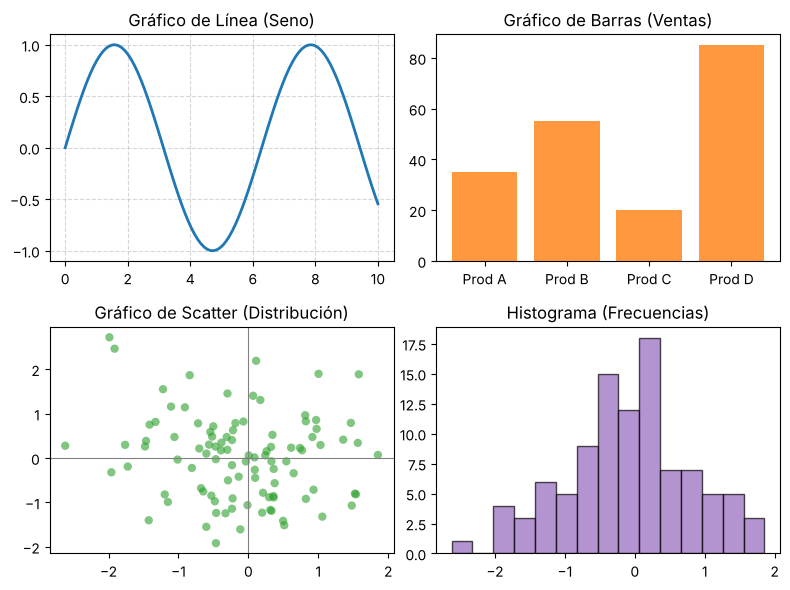

In [4]:
# 🎯 EJERCICIO 4: Subplots 2x2
import matplotlib.pyplot as plt
import numpy as np

# Generación de datos dummy
np.random.seed(42)
x = np.linspace(0, 10, 100)
y = np.sin(x)
categorias = ["Prod A", "Prod B", "Prod C", "Prod D"]
valores = [35, 55, 20, 85]
random_x = np.random.randn(100)
random_y = np.random.randn(100)

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
print(fig)
print(axes)

# 1. Gráfico de Línea (Top-Left)
axes[0, 0].plot(x, y, color="tab:blue", linewidth=2)
axes[0, 0].set_title("Gráfico de Línea (Seno)")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. Gráfico de Barras (Top-Right)
axes[0, 1].bar(categorias, valores, color="tab:orange", alpha=0.8)
axes[0, 1].set_title("Gráfico de Barras (Ventas)")

# 3. Gráfico de Dispersión / Scatter (Bottom-Left)
axes[1, 0].scatter(random_x, random_y, color="tab:green", alpha=0.6, edgecolors="none")
axes[1, 0].set_title("Gráfico de Scatter (Distribución)")
axes[1, 0].axhline(0, color="grey", lw=0.8)
axes[1, 0].axvline(0, color="grey", lw=0.8)

# 4. Histograma (Bottom-Right)
axes[1, 1].hist(random_x, bins=15, color="tab:purple", edgecolor="black", alpha=0.7)
axes[1, 1].set_title("Histograma (Frecuencias)")

plt.tight_layout()
plt.savefig("/tmp/ejercicio_subplots.png", dpi=80)
plt.show()

### 🔴 Ejercicio 5 — Gráfico personalizado
Gráfico con título, etiquetas de ejes, leyenda, grilla, colores y guardado como PNG.


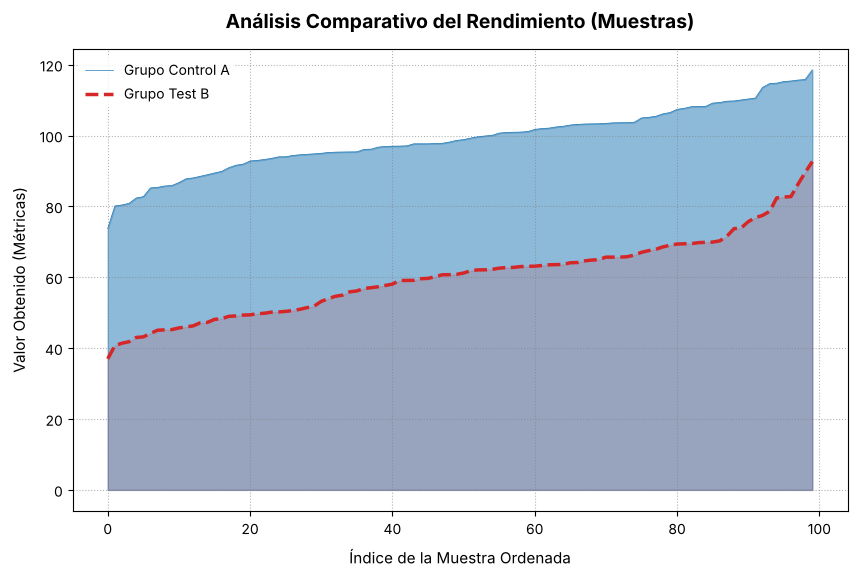

In [5]:
# 🎯 EJERCICIO 5: Gráfico completamente personalizado
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)
datos_a = np.random.normal(100, 10, 100)
datos_b = np.random.normal(60, 12, 100)

# Ordenamos para armar un gráfico de líneas/áreas suave
datos_a.sort()
datos_b.sort()

plt.figure(figsize=(10, 6))

# Trazar curvas con personalización de estilos, etiquetas y áreas rellenas
plt.plot(datos_a, label="Grupo Control A", color="#1f77b4", linewidth=0.5, linestyle="-")
plt.fill_between(range(len(datos_a)), datos_a, color="#1f77b4", alpha=0.50, interpolate=True)

plt.plot(datos_b, label="Grupo Test B", color="#d62728", linewidth=2.5, linestyle="--")
plt.fill_between(range(len(datos_b)), datos_b, color="#d62728", alpha=0.15, interpolate=True)

# Título y etiquetas de ejes
plt.title("Análisis Comparativo del Rendimiento (Muestras)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Índice de la Muestra Ordenada", fontsize=11, labelpad=8)
plt.ylabel("Valor Obtenido (Métricas)", fontsize=11, labelpad=8)

# Agregar grilla con estilo atenuado
plt.grid(True, linestyle=":", alpha=0.6, color="gray")

# Leyenda posicionada estratégicamente
plt.legend(loc="upper left", fontsize=10, frameon=True, facecolor="white", edgecolor="none")

# Guardar y mostrar
plt.savefig("/tmp/grafico_personalizado.png", dpi=300, bbox_inches="tight")
plt.show()

## Desafío extra 🔴

Implementar un **análisis de cohortes** de usuarios:
- Generar datos sintéticos de usuarios (fecha de registro + compras mensuales)
- Calcular retention por cohorte (% de usuarios que compran en mes 0, 1, 2, 3...)
- Crear un heatmap de retención con matplotlib


Retención por cohorte (%):
meses_desde_registro      0     1     2     3     4     5
cohorte                                                  
2025-01               100.0  56.2  35.0  27.5  32.5  28.7
2025-02               100.0  54.2  49.4  43.4  28.9   NaN
2025-03               100.0  54.9  38.0  31.0   NaN   NaN
2025-04               100.0  53.9  37.1   NaN   NaN   NaN
2025-05               100.0  50.5   NaN   NaN   NaN   NaN
2025-06               100.0   NaN   NaN   NaN   NaN   NaN


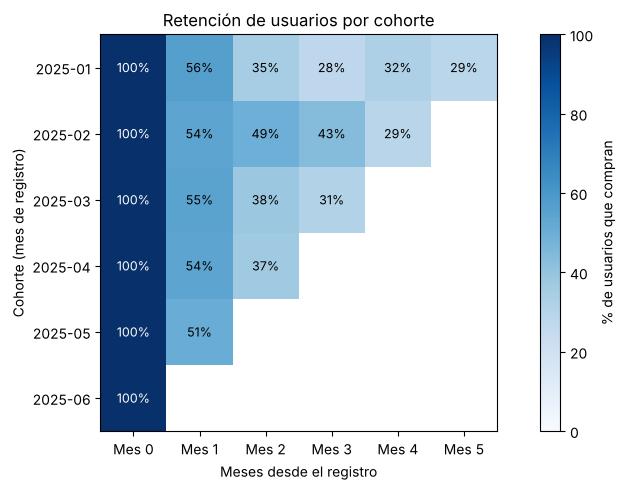

In [6]:
# 🔴 Desafío: Análisis de cohortes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
# Generar datos: 500 usuarios registrados entre ene y jun 2025
n_usuarios = 500
fechas_registro = pd.date_range("2025-01-01", "2025-06-30", freq="D")
df_usuarios = pd.DataFrame({
    "usuario_id": range(1, n_usuarios + 1),
    "fecha_registro": np.random.choice(fechas_registro, n_usuarios),
})
df_usuarios["cohorte"] = df_usuarios["fecha_registro"].dt.to_period("M")

# Compras mensuales sintéticas: todos compran el mes en que se registran
# y después la probabilidad de volver a comprar va bajando mes a mes
ultimo_mes = pd.Period("2025-06", "M")
compras = []
for usuario_id, cohorte in zip(df_usuarios["usuario_id"], df_usuarios["cohorte"]):
    for meses_desde_registro in range(6):
        mes = cohorte + meses_desde_registro
        if mes > ultimo_mes:
            break
        probabilidad = 1.0 if meses_desde_registro == 0 else 0.55 * 0.8 ** (meses_desde_registro - 1)
        if np.random.rand() < probabilidad:
            compras.append({"usuario_id": usuario_id, "cohorte": cohorte, "meses_desde_registro": meses_desde_registro})
df_compras = pd.DataFrame(compras)

# Retención = usuarios que compran en el mes N / usuarios de la cohorte
activos = df_compras.groupby(["cohorte", "meses_desde_registro"])["usuario_id"].nunique().unstack()
tamanio_cohorte = df_usuarios.groupby("cohorte")["usuario_id"].count()
retencion = activos.div(tamanio_cohorte, axis=0) * 100

print("Retención por cohorte (%):")
print(retencion.round(1).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(9, 5))
imagen = ax.imshow(retencion.values, cmap="Blues", vmin=0, vmax=100)
for i in range(retencion.shape[0]):
    for j in range(retencion.shape[1]):
        valor = retencion.values[i, j]
        if not np.isnan(valor):
            ax.text(j, i, f"{valor:.0f}%", ha="center", va="center",
                    color="white" if valor > 60 else "black", fontsize=9)
ax.set_xticks(range(retencion.shape[1]), [f"Mes {m}" for m in retencion.columns])
ax.set_yticks(range(retencion.shape[0]), [str(c) for c in retencion.index])
ax.set_xlabel("Meses desde el registro")
ax.set_ylabel("Cohorte (mes de registro)")
ax.set_title("Retención de usuarios por cohorte")
fig.colorbar(imagen, label="% de usuarios que compran")
plt.tight_layout()
plt.show()

## Resumen de conceptos

| Herramienta | Función | Descripción |
|---|---|---|
| pd.read_csv / to_csv | `df = pd.read_csv(path)` | Leer/escribir CSV |
| merge | `pd.merge(df1, df2, on, how)` | JOIN entre DataFrames |
| groupby + agg | `df.groupby(col).agg({...})` | Agregar múltiples estadísticas |
| pivot_table | `df.pivot_table(values, index, columns)` | Tabla dinámica |
| fillna | `df.fillna(valor)` | Rellenar nulos |
| dropna | `df.dropna(subset=[col])` | Eliminar filas con nulos |
| plt.subplots | `fig, ax = plt.subplots(n, m)` | Crear panel de gráficos |
| ax.plot | `ax.plot(x, y)` | Gráfico de líneas |
| ax.bar / barh | `ax.bar(x, y)` | Gráfico de barras |
| ax.scatter | `ax.scatter(x, y)` | Gráfico de dispersión |
| ax.hist | `ax.hist(x, bins)` | Histograma |
| savefig | `plt.savefig(path, dpi)` | Guardar imagen |
